# Chromaffin maturation across embryonic stages

Akkuratova, Faure and colleagues traced embryonic mouse adrenal pro-chromaffin cells (ChC1) toward an oxygen-sensing population (ChC2) and a broad maturing chromaffin population (ChC3). Their paper already described these paths using trajectory analysis and RNA velocity. Here we ask a narrower question. **At the same annotated starting state, how much modeled reach do early and late adrenal cells have toward the same two endpoints?** ChC3 encompasses further heterogeneity, including adrenergic and noradrenergic maturation.

The notebook joins the authors’ cell annotations to their nine original Smart-seq2 velocyto looms, fits RNA velocity and reports what happens when the graph can borrow endpoints across stages. [Original study](https://doi.org/10.3389/fendo.2022.1020000) · [GEO GSE204700](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE204700)

This is a published, trajectory-inferred developmental fork. Clonal tracking would be needed to verify individual ChC1 cell fates.

## Inputs and cell selection

Run inside the scCS source checkout with the velocity dependencies installed. The first run downloads and verifies the uncompressed GEO files in `data/scored_cases/`. The shared loader and SHA-256 manifest are in `benchmarks/validation/`. The final cell saves the fitted graph and tables for inspection.

In [1]:
from pathlib import Path
import sys
import importlib.metadata as metadata
import platform
import json
import numpy as np
import pandas as pd
import scanpy as sc
import scvelo as scv
import scCS
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "benchmarks/validation/real_pair_cases.py").is_file()
)
sys.path.insert(0, str(PROJECT))

matplotlib.use("module://matplotlib_inline.backend_inline", force=True)
CASE = "chromaffin"
ROOT = "ChC 1"
FATES = ["ChC 2", "ChC 3"]
CONDITIONS = ["E12.5-E14.5", "E16.5"]

SEED = 19
np.random.seed(SEED)
DATA = PROJECT / "data" / "scored_cases"
OUTPUT = PROJECT / "tutorial_outputs" / CASE
OUTPUT.mkdir(parents=True, exist_ok=True)
versions = {
    p: metadata.version(p)
    for p in ["scCS-py", "scanpy", "scvelo", "anndata", "numpy", "pandas", "scipy", "h5py", "numba"]
}
print("Python", platform.python_version(), versions)

Python 3.12.14 {'scCS-py': '1.0.1.dev0', 'scanpy': '1.12.6', 'scvelo': '0.3.4', 'anndata': '0.13.4', 'numpy': '2.5.5', 'pandas': '2.3.3', 'scipy': '1.18.1', 'h5py': '3.16.0', 'numba': '0.68.1'}


Keep adrenal cells from E12.5 through E16.5, pooling E12.5, E13.5 and E14.5 as the early window. Display the complete deposited annotation first so the tissue restriction and late-stage root scarcity are visible. Each selected stage maps to a single contributing plate. Stage, plate and changing cell composition can all influence the comparison.

In [2]:
from benchmarks.validation.real_pair_cases import chromaffin_metadata, load_case, model_genes

annotations = chromaffin_metadata(DATA)
display(pd.crosstab([annotations.location, annotations.devtime], annotations.annot))

annot             ChC 1  ChC 2  ChC 3   SC  SCP  SCP-ChC prog.
location devtime                                              
Adrenal  E12.5      144     19      0    0   31            147
         E13.5       54     82      3    0   75             34
         E14.5       28      2      7    0   33             73
         E16.5       34      3     51   14    9             19
         E18.5        0      0      2   35    1              2
         P2           1      0     31  228   13              0
ZO       E14.5       21     19      0    0   72             13
         E16.5        1      8      1   33   18              0

In [3]:
raw, inventory, full = load_case(CASE, DATA)
display(inventory)
counts = pd.crosstab([full.condition, full.library], full.state)
display(counts)
modeled_counts = pd.crosstab([raw.obs.condition, raw.obs.library], raw.obs.state)
display(modeled_counts)
assert int(inventory.eligible.sum()) == len(full)
assert int(inventory.modeled.sum()) == raw.n_obs
for name, table in [
    ("input_inventory", inventory),
    ("eligible_state_counts", counts),
    ("modeled_state_counts", modeled_counts),
]:
    table.to_csv(OUTPUT / (name + ".csv"), index=name != "input_inventory")
raw.obs.to_csv(OUTPUT / "modeled_cell_metadata.csv")
adata = model_genes(raw)
del raw
print(adata.shape, "cells × genes selected for velocity preprocessing")

(862, 1500) cells × genes selected for velocity preprocessing


,library,loom_cells,eligible,modeled
0,GSM6186008,384,341,341
1,GSM6186009,383,248,248
2,GSM6186010,384,143,143
3,GSM6186011,384,130,130
4,GSM6186012,384,0,0
5,GSM6186013,384,0,0
6,GSM6186014,384,0,0
7,GSM6186015,384,0,0
8,GSM6186016,384,0,0


state                   ChC 1  ChC 2  ChC 3  SC  SCP  SCP-ChC prog.
condition   library                                                
E12.5-E14.5 GSM6186008    144     19      0   0   31            147
            GSM6186009     54     82      3   0   75             34
            GSM6186010     28      2      7   0   33             73
E16.5       GSM6186011     34      3     51  14    9             19

state                   ChC 1  ChC 2  ChC 3  SC  SCP  SCP-ChC prog.
condition   library                                                
E12.5-E14.5 GSM6186008    144     19      0   0   31            147
            GSM6186009     54     82      3   0   75             34
            GSM6186010     28      2      7   0   33             73
E16.5       GSM6186011     34      3     51  14    9             19

## Fit RNA velocity

Start with measured spliced and unspliced layers. Select up to 1,500 expressed genes by spliced overdispersion, excluding mitochondrial, ribosomal-protein and immunoglobulin families specified in the loader. Normalize the selected matrix, compute the expression neighborhood and fit dynamical kinetics for up to 250 scVelo candidate genes. scVelo retained 223 velocity genes in this fit. The plots show the fitted field, its local confidence and phase portraits for the two velocity genes with the highest fit likelihood. The ordering used to define late anchors is the authors’ continuous differentiation ordering, calculated as one minus CytoTRACE. The sampled state labels and the kinetic fit serve different roles.

In [4]:
scv.pp.filter_genes(adata, min_shared_counts=10)
scv.pp.normalize_per_cell(adata)
sc.pp.log1p(adata)
sc.pp.pca(adata, n_comps=30, random_state=SEED)
sc.pp.neighbors(adata, n_neighbors=30, n_pcs=30, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)
scv.pp.moments(adata, n_neighbors=None, n_pcs=None)
# Limit the kinetic fit to 250 well-measured genes with high velocity signal.
scv.tl.recover_dynamics(adata, n_top_genes=250, max_iter=20, n_jobs=1, show_progress_bar=False)
scv.tl.velocity(adata, mode="dynamical")
scv.tl.velocity_graph(adata, n_jobs=1, show_progress_bar=False)
scv.tl.velocity_confidence(adata)
if CASE == "chromaffin":
    adata.obs["ordering"] = 1 - adata.obs["CytoTRACE"]
else:
    # Represent each library equally when selecting the central activated B root.
    pcs = adata.obsm["X_pca"][:, :30]
    root_positions = np.flatnonzero(adata.obs.state.eq(ROOT))
    centers = [
        pcs[root_positions[adata.obs.library.iloc[root_positions].eq(k).to_numpy()]].mean(axis=0)
        for k in sorted(adata.obs.library.unique())
    ]
    seed = root_positions[
        np.argmin(((pcs[root_positions] - np.mean(centers, axis=0)) ** 2).sum(axis=1))
    ]
    scv.tl.velocity_pseudotime(adata, root_key=str(adata.obs_names[seed]))
    adata.obs["ordering"] = adata.obs["velocity_pseudotime"]
transition = scCS.get_scvelo_transition_matrix(adata)
assert np.isfinite(adata.obs.ordering).all()
assert transition.shape == (adata.n_obs, adata.n_obs) and np.isfinite(transition.data).all()
np.testing.assert_allclose(np.asarray(transition.sum(axis=1)).ravel(), 1, atol=1e-6)
print(
    "Kinetic fits:",
    adata.var.fit_likelihood.notna().sum(),
    "| velocity genes:",
    adata.var.velocity_genes.sum(),
)
display(
    adata.obs.groupby(["condition", "state"], observed=True)[["ordering", "velocity_confidence"]]
    .median()
    .round(3)
)

Normalized count data: X, spliced, unspliced.
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 1/9 cores)
    finished (0:00:26) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/9 cores)
    finished (0:00:00) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
--> added 'velocity_length' (adata.obs)
--> added 'velocity_confidence' (adata.obs)
--> added 'velocity_confidence_transition' (adata.obs)
Kinetic fits: 250 | velocity genes: 223


ordering  velocity_confidence
condition   state                                       
E12.5-E14.5 ChC 1             0.164                0.910
            ChC 2             0.342                0.925
            ChC 3             0.432                0.797
            SCP               0.629                0.850
            SCP-ChC prog.     0.437                0.867
E16.5       ChC 1             0.289                0.750
            ChC 2             0.340                0.841
            ChC 3             0.424                0.881
            SC                0.765                0.841
            SCP               0.708                0.779
            SCP-ChC prog.     0.488                0.816

computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


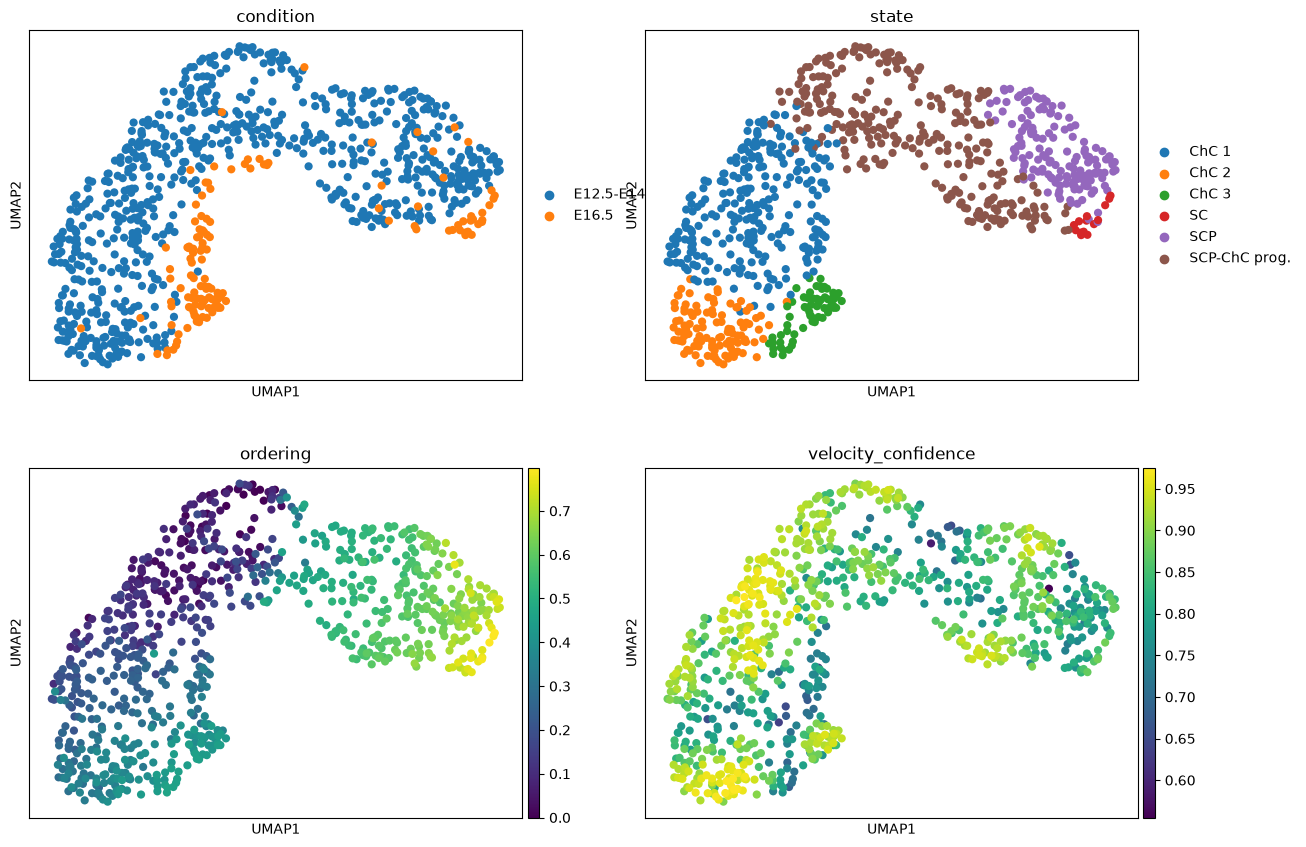

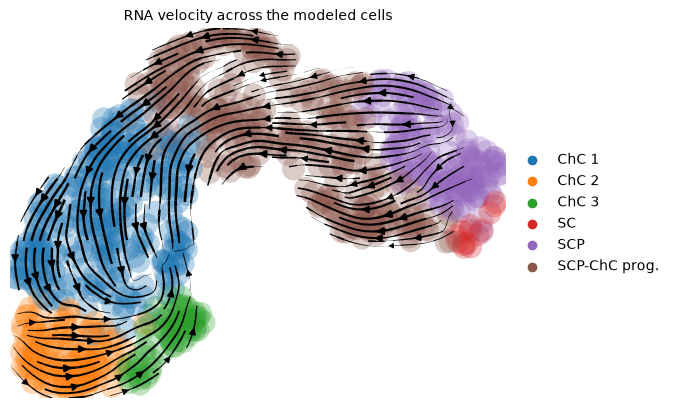

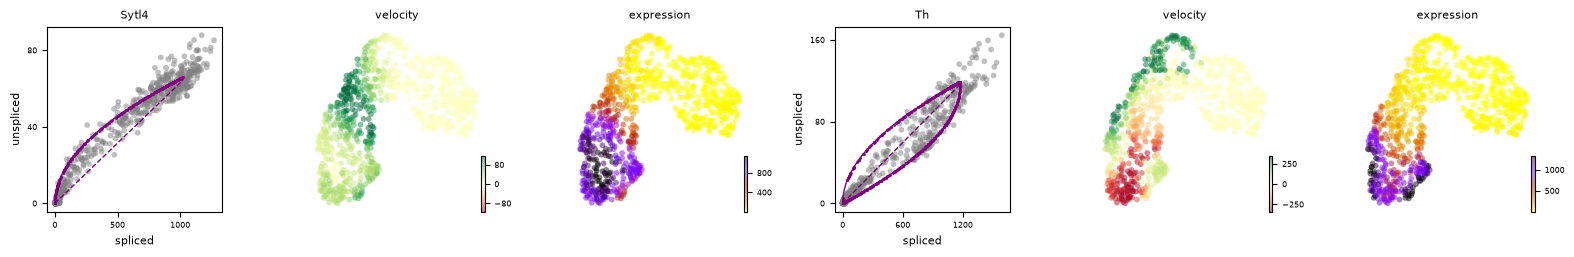

In [5]:
sc.pl.umap(
    adata, color=["condition", "state", "ordering", "velocity_confidence"], ncols=2, show=False
)
plt.show()
scv.pl.velocity_embedding_stream(adata, basis="umap", color="state", legend_loc="right margin",
                                 title="RNA velocity across the modeled cells", show=False)
plt.show()
genes = (
    adata.var.loc[adata.var.velocity_genes]
    .sort_values("fit_likelihood", ascending=False)
    .head(2)
    .index.tolist()
)
if genes:
    scv.pl.velocity(adata, var_names=genes, ncols=2, show=False)
    plt.show()

## Compare roots on the shared graph

PairScorer uses the annotated root and branches to define the scored population and anchors. The first-hit calculation can traverse other cells on the full RNA-velocity graph. The primary fit pools transitions across groups. For each endpoint, it takes the upper decile of the shared ordering, with a minimum of three anchors where available. An effective horizon of 64 discounts longer paths. **DFR** measures discounted reach to either endpoint. **CFA** describes the relative destination among roots with defined affinity. Their per-cell product gives each endpoint’s contribution. The tables retain the total and defined root counts. UFP is the remaining unresolved probability.

In [6]:
def fit_pair(scope, quantile):
    scorer = scCS.PairScorer(adata, root=ROOT, branches=FATES, obs_key="state",
                             condition_obs_key="condition", condition_order=CONDITIONS,
                             replicate_obs_key="library" if CASE == "bcell" else None)
    scorer.build_embedding(ordering_metric="ordering", cache_subset=False, verbose=False)
    scorer.fit(transition_matrix=transition, transition_scope=scope, scoring_mode="future_fate",
               future_fate_options={"effective_horizon": 64, "anchor_quantile": quantile,
                                    "min_anchor_cells": 3}, verbose=False)
    results = scorer.score_all_conditions(population="root", min_cells=1, min_replicates=1,
                                          write_to_adata=False, verbose=False)
    return scorer, results


def root_table(results):
    frames = []
    for condition, r in results.items():
        assert list(r.fate_names) == FATES
        t = adata.obs.loc[r.cell_ids, ["library", "state"]].copy()
        assert t.state.eq(ROOT).all()
        t["condition"] = condition
        t["defined"] = r.affinity_defined
        t["DFR"] = r.commitment_strength
        t["UFP"] = r.unresolved_probability
        t["coverage"] = r.transition_coverage
        for j, fate in enumerate(FATES):
            t["CFA " + fate] = r.directional_affinity[:, j]
            t["contribution " + fate] = r.commitment_contribution[:, j]
        finite = r.affinity_defined
        assert np.isnan(r.directional_affinity[~finite]).all()
        np.testing.assert_allclose(r.directional_affinity[finite].sum(axis=1), 1)
        np.testing.assert_allclose(r.commitment_contribution.sum(axis=1), t.DFR, atol=1e-9)
        np.testing.assert_allclose(t.DFR + t.UFP, 1, atol=1e-9)
        frames.append(t)
    return pd.concat(frames)


def summarize(frame, keys):
    grouped = frame.groupby(keys, observed=True)
    out = grouped[["defined","DFR","UFP","coverage"] + ["CFA " + f for f in FATES]
                  + ["contribution " + f for f in FATES]].mean()
    out.insert(0, "defined_roots", grouped.defined.sum())
    out.insert(0, "roots", grouped.size())
    return out


pair, results = fit_pair("pooled", .90)
cells = root_table(results)
assert set(cells.index) == set(adata.obs_names[adata.obs.state.eq(ROOT)])
by_condition = summarize(cells, ["condition"]).reindex(CONDITIONS)
by_library = summarize(cells, ["condition", "library"])
display(by_condition.round(4))
display(by_library.round(4))
cells.to_csv(OUTPUT / "root_cells.csv")
by_library.to_csv(OUTPUT / "root_scores_by_library.csv")
by_condition.to_csv(OUTPUT / "root_scores_by_condition.csv")

,roots,defined_roots,defined,DFR,UFP,coverage,CFA ChC 2,CFA ChC 3,contribution ChC 2,contribution ChC 3
condition,,,,,,,,,,
E12.5-E14.5,226,226,1.0,0.5481,0.4519,0.9979,0.7007,0.2993,0.3841,0.1640
E16.5,34,34,1.0,0.5049,0.4951,0.9928,0.6836,0.3164,0.3451,0.1598


roots  ...  contribution ChC 3
condition   library            ...                    
E12.5-E14.5 GSM6186008    144  ...              0.1605
            GSM6186009     54  ...              0.1641
            GSM6186010     28  ...              0.1818
E16.5       GSM6186011     34  ...              0.1598

[4 rows x 10 columns]

## How much did the scores change?

The contrast is **E16.5 minus E12.5-E14.5**. DFR measures discounted access to either destination. Each endpoint contribution averages over all roots, including roots with zero reach. CFA averages over defined roots. Read its denominator alongside the change. Each cell has equal weight within its group. The values describe the sampled roots.

,roots,defined roots
condition,,
E12.5-E14.5,226,226
E16.5,34,34


condition,E12.5-E14.5,E16.5,change
DFR,0.5481,0.5049,-0.0432
UFP,0.4519,0.4951,0.0432
defined fraction,1.0000,1.0000,0.0000
contribution ChC 2,0.3841,0.3451,-0.0390
contribution ChC 3,0.1640,0.1598,-0.0042
CFA ChC 2,0.7007,0.6836,-0.0171
CFA ChC 3,0.2993,0.3164,0.0171


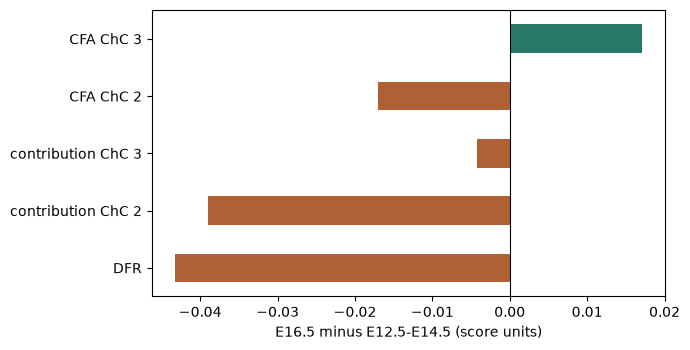

In [10]:
comp = cells.copy()
arms = ['E12.5-E14.5', 'E16.5']
affinities = ['CFA ChC 2', 'CFA ChC 3']
contributions = ['contribution ChC 2', 'contribution ChC 3']
comp["defined fraction"] = comp[affinities].notna().all(axis=1)
metrics = ["DFR", "UFP", "defined fraction"] + contributions + affinities
arm = comp.groupby("condition", observed=True)[metrics].mean().reindex(arms)
effect = arm.T.copy()
effect["change"] = effect[arms[1]] - effect[arms[0]]
counts = (
    comp.groupby("condition", observed=True)["defined fraction"].agg(["size", "sum"]).reindex(arms)
)
display(counts.rename(columns={"size":"roots","sum":"defined roots"}))
display(effect.round(4))
np.testing.assert_allclose(effect.loc[contributions,"change"].sum(),effect.loc["DFR","change"],atol=1e-9)
effect.to_csv(OUTPUT / "condition_contrast.csv")
panel = effect.loc[["DFR"] + contributions + affinities,"change"]
ax = panel.plot.barh(figsize=(7,3.6),color=np.where(panel>=0,"#287867","#af6035"))
ax.axvline(0,color="black",lw=.8)
ax.set_xlabel(arms[1] + " minus " + arms[0] + " (score units)")
plt.tight_layout()
plt.show()

Mean DFR changed by **-0.0432**. The decrease in ChC2 contribution accounts for most of the decrease in total reach. Each contrast is stage-associated, with one late plate. The stage-restricted fit tests dependence on cross-stage endpoints.

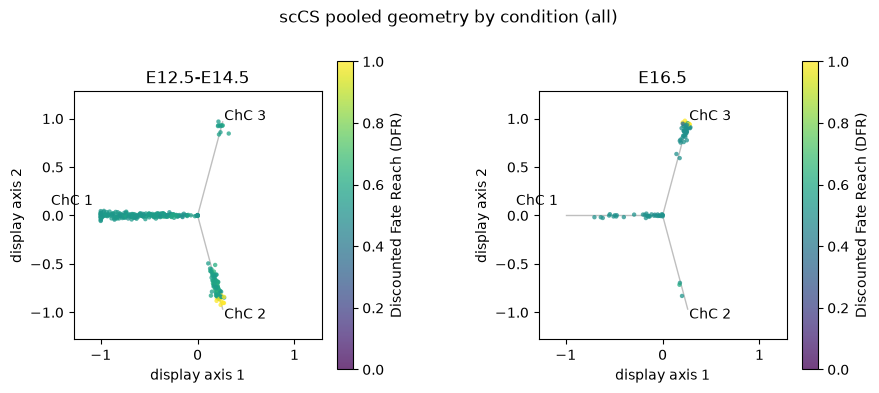

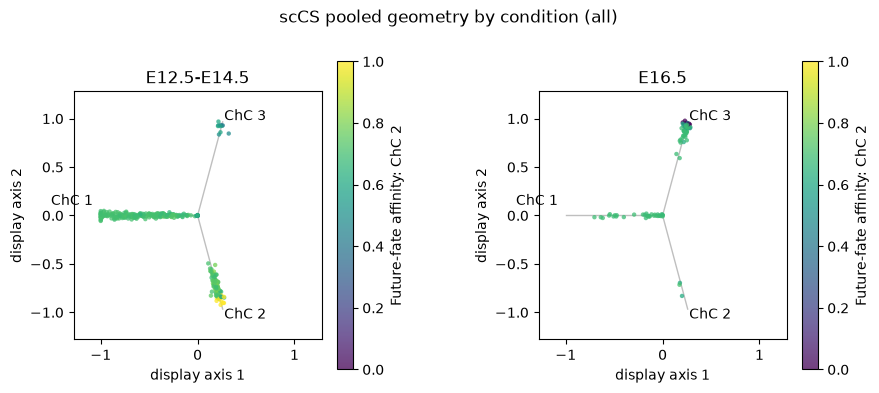

In [7]:
for metric in ["future_fate_reach", "future_fate_affinity:" + FATES[0]]:
    pair.plot_star_grid(
        results, color_by=metric, population="all", ncols=2, figsize_per_panel=(5, 4)
    )
    plt.show()

## Test dependence on anchors and graph scope

Count actual endpoint anchors by group. Then broaden the anchor set to the upper half of each endpoint label and remove between-condition transitions in a second fit. The neighborhood, kinetic parameters and ordering stay pooled. Blocking can isolate roots or leave a group without a given anchor; a zero under those circumstances is a property of the design.

In [8]:
checks, anchors = [], []
scopes = ["pooled", "condition"] + (["replicate"] if CASE == "bcell" else [])
for scope in scopes:
    for quantile in [.5, .9]:
        scorer, res = (
            (pair, results) if (scope, quantile) == ("pooled", 0.9) else fit_pair(scope, quantile)
        )
        summ = summarize(root_table(res), ["condition"])
        checks.append(summ.assign(scope=scope, anchor_quantile=quantile).reset_index())
        if scope == "pooled":
            scorer.result.write_to_adata(adata)
            anchor_ids = adata.uns["sccs_v08"]["future_fate"]["anchor_cell_ids"]
            for fate, ids in anchor_ids.items():
                for cond in CONDITIONS:
                    names = adata.obs_names[adata.obs.condition.eq(cond)]
                    anchors.append((quantile, fate, cond, len(names.intersection(ids))))
anchor_counts = pd.DataFrame(anchors, columns=["quantile", "endpoint", "condition", "anchors"])
diagnostics = pd.concat(checks, ignore_index=True)
display(anchor_counts.pivot(index=["quantile","endpoint"], columns="condition", values="anchors"))
display(diagnostics[["scope", "anchor_quantile", "condition", "roots", "defined_roots", "DFR",
                     "CFA " + FATES[0], "contribution " + FATES[0]]].round(4))
anchor_counts.to_csv(OUTPUT / "anchor_counts.csv", index=False)
diagnostics.to_csv(OUTPUT / "graph_sensitivity.csv", index=False)

condition          E12.5-E14.5  E16.5
quantile endpoint                    
0.5      ChC 2              52      1
         ChC 3               7     24
0.9      ChC 2              11      0
         ChC 3               0      7

,scope,anchor_quantile,condition,roots,defined_roots,DFR,CFA ChC 2,contribution ChC 2
0,pooled,0.5,E12.5-E14.5,226,226,0.8925,0.7610,0.6809
1,pooled,0.5,E16.5,34,34,0.8319,0.6173,0.5132
2,pooled,0.9,E12.5-E14.5,226,226,0.5481,0.7007,0.3841
3,pooled,0.9,E16.5,34,34,0.5049,0.6836,0.3451
4,condition,0.5,E12.5-E14.5,226,226,0.8884,0.8472,0.7536
5,condition,0.5,E16.5,34,34,0.5216,0.0009,0.0005
6,condition,0.9,E12.5-E14.5,226,226,0.5046,1.0000,0.5046
7,condition,0.9,E16.5,34,34,0.0546,0.0000,0.0000


## Do late adrenal progenitors lose access to the oxygen-sensing chromaffin state?

The mouse adrenal gland contains an oxygen-sensing chromaffin population (ChC2) and a broader maturing chromaffin population (ChC3). The published trajectory places pro-chromaffin ChC1 cells upstream of both. On a common developmental reference, ChC1 cells from E12.5–E14.5 and E16.5 retained similar conditional affinity for ChC2 (0.701 and 0.684). All 226 early and 34 late roots had defined affinity. Mean reach to either mature population decreased from 0.548 to 0.505.

This distinction matters because the available mature cells change with age. All 11 upper-decile ChC2 anchors came from the early window and all seven ChC3 anchors from E16.5. Restricting each progenitor to cells of its own stage makes its apparent fate exclusive. The pooled result supports continued access to the oxygen-sensing program. Testing loss of intrinsic competence in late ChC1 cells would require both endpoints to be sampled at the same stage or descendants to be traced. [Akkuratova, Faure et al.](https://doi.org/10.3389/fendo.2022.1020000)

In [9]:
pair.result.write_to_adata(adata)
adata.obsp["T_velocity"] = transition
adata.write_h5ad(OUTPUT / "fitted.h5ad", compression="gzip")
adata.var.filter(regex=r"^fit_|^velocity_genes$").to_csv(OUTPUT / "gene_fits.csv")
(OUTPUT / "versions.json").write_text(
    json.dumps({"python": platform.python_version(), "packages": versions, "seed": SEED}, indent=2)
)
print(f"Saved model and audit tables in tutorial_outputs/{CASE}/")

Saved model and audit tables in tutorial_outputs/chromaffin/
